# Evaluation 1 – Token consumption and response time

Covers two of the five evaluation dimensions:

* **Tokens** – how much text the model reads (`tokens_in`) and writes (`tokens_out`) per question,
  plus the tokens the *peer* agent spends answering the KQML `ask` (`peer_tokens`).
  `tokens_total = tokens_in + tokens_out + peer_tokens`. This sets the cost.
* **Response time** – how long each pipeline step and the whole question take (`wall_ms`),
  and how that grows with question complexity.

**Data:** 4 models × 100 questions × 2 agents (Agent-001, Agent-002) × 5 repetitions = 4 000 asks.

| run | models |
|---|---|
| 14 | Qwen3-8B (base), Qwen3-8B + QLoRA (fine-tuned) – local |
| 18 | GPT-4o mini, Claude Haiku 5.5 – API |

Correctness, consistency and symmetry are analysed in later notebooks.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA_DIR = Path("..") / "data"
OUT_DIR = Path("outputs") / "01_tokens_response_time"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Fixed model order and colour: a model keeps its colour in every chart.
MODELS = ["gpt-4o-mini", "claude-haiku", "qwen3-8b", "qwen3-8b-lora"]
MODEL_LABEL = {
    "gpt-4o-mini": "GPT-4o mini",
    "claude-haiku": "Claude Haiku 5.5",
    "qwen3-8b": "Qwen3-8B",
    "qwen3-8b-lora": "Qwen3-8B + QLoRA",
}
MODEL_COLOR = {
    "gpt-4o-mini": "#2a78d6",
    "claude-haiku": "#eb6834",
    "qwen3-8b": "#1baf7a",
    "qwen3-8b-lora": "#eda100",
}
CATEGORIES = [
    "DATA_LOOKUP", "GEOMETRY_LOOKUP", "SPATIAL_ADJACENCY", "SPATIAL_DIRECTION",
    "SPATIAL_DISTANCE", "SPATIAL_OPERATION", "SPATIAL_RELATIONSHIP_BUFFER", "UNRELATED",
]

TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
GRID = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_2,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": TEXT_2,
    "ytick.color": TEXT_2,
    "legend.frameon": False,
    "font.size": 10,
})


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()

## 1. Load the per-model result files

In [7]:
files = sorted(f for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_*_runs-*.csv")
               if "summary" not in f.name)
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)
df["model"] = pd.Categorical(df["model"], categories=MODELS, ordered=True)

# Time in seconds, and the parts of wall time that are not one of the four named steps.
STEPS = ["ms_classify", "ms_extract", "ms_sql", "ms_kqml"]
df["wall_s"] = df["wall_ms"] / 1000
df["ms_other"] = df["ms_agent"] - df[STEPS].sum(axis=1)   # agent time outside the four steps
df["ms_outside"] = df["wall_ms"] - df["ms_agent"]        # HTTP + test harness, outside the agent
df["used_kqml"] = df["kqml_turns"] > 0

for f in files:
    print(f.relative_to(DATA_DIR))
print()
print(df.groupby(["model", "agent_name"], observed=True).size().unstack())

evaluation_per_model_runs-14\evaluation_qwen3-8b-lora_runs-14.csv
evaluation_per_model_runs-14\evaluation_qwen3-8b_runs-14.csv
evaluation_per_model_runs-18\evaluation_claude-haiku_runs-18.csv
evaluation_per_model_runs-18\evaluation_gpt-4o-mini_runs-18.csv

agent_name     Agent-001  Agent-002
model                              
gpt-4o-mini          500        500
claude-haiku         500        500
qwen3-8b             500        500
qwen3-8b-lora        500        500


In [8]:
# Sanity checks – these must all hold before the numbers below can be trusted.
checks = {
    "every ask returned HTTP 200": (df["http_status"] == 200).all(),
    "tokens_total = in + out + peer": (df["tokens_total"] == df["tokens_in"] + df["tokens_out"] + df["peer_tokens"]).all(),
    "100 questions per model": (df.groupby("model", observed=True)["qid"].nunique() == 100).all(),
    "5 reps per question/agent": (df.groupby(["model", "qid", "agent_name"], observed=True).size() == 5).all(),
    "no step time is missing": df[STEPS].notna().all().all(),
    "peer_tokens = 0 when no KQML turn": (df.loc[~df["used_kqml"], "peer_tokens"] == 0).all(),
}
for name, ok in checks.items():
    print(("OK   " if ok else "FAIL ") + name)

print()
print("answer_status per model:")
print(pd.crosstab(df["model"], df["answer_status"]))

OK   every ask returned HTTP 200
OK   tokens_total = in + out + peer
OK   100 questions per model
OK   5 reps per question/agent
OK   no step time is missing
OK   peer_tokens = 0 when no KQML turn

answer_status per model:
answer_status  complete  error  not-found  partial-complete  rejected
model                                                                
gpt-4o-mini         780      0         68                60        92
claude-haiku        800      0         70                60        70
qwen3-8b            800     10         80                50        60
qwen3-8b-lora       790      0         80                70        60


### 1.1 Cross-check against the tool's own summary files

The `evaluation_summary_per_model_runs-*.csv` files are computed over **Agent-001 asks only**
(100 questions × 5 reps = 500). Recomputing them from the raw rows confirms that the raw data and
the summaries agree. Everything after this section uses **both agents** (1 000 asks per model) unless
stated otherwise.

In [10]:
summary = pd.concat([pd.read_csv(f, encoding="utf-8-sig")
                     for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_summary_*.csv")])
summary = summary.set_index("model").loc[MODELS]

a1 = df[df["agent_name"] == "Agent-001"].groupby("model", observed=True)
recomputed = pd.DataFrame({
    "tokens_in_mean": a1["tokens_in"].mean(),
    "tokens_out_mean": a1["tokens_out"].mean(),
    "tokens_total_mean": a1["tokens_total"].mean(),
    "cost_usd_sum": a1["cost_usd"].sum(),
    "wall_ms_mean": a1["wall_ms"].mean(),
    "wall_ms_median": a1["wall_ms"].median(),
    "ms_sql_mean": a1["ms_sql"].mean(),
})
diff = (recomputed - summary[recomputed.columns]).abs()
print("largest absolute difference per column (should be ~0, rounding only):")
print(diff.max().round(4))

largest absolute difference per column (should be ~0, rounding only):
tokens_in_mean       0.0160
tokens_out_mean      0.0400
tokens_total_mean    0.0480
cost_usd_sum         0.0022
wall_ms_mean         0.0498
wall_ms_median       0.0000
ms_sql_mean          0.0488
dtype: float64


## 2. Tokens

### 2.1 Tokens per question, per model

In [11]:
TOKEN_COLS = ["tokens_in", "tokens_out", "peer_tokens", "tokens_total"]

tok = df.groupby("model", observed=True).agg(
    asks=("qid", "size"),
    tokens_in_mean=("tokens_in", "mean"),
    tokens_out_mean=("tokens_out", "mean"),
    peer_tokens_mean=("peer_tokens", "mean"),
    tokens_total_mean=("tokens_total", "mean"),
    tokens_total_median=("tokens_total", "median"),
    tokens_total_p95=("tokens_total", lambda s: s.quantile(0.95)),
    tokens_total_sum=("tokens_total", "sum"),
    llm_calls_mean=("llm_calls", "mean"),
)
tok["output_share_%"] = tok["tokens_out_mean"] / (tok["tokens_in_mean"] + tok["tokens_out_mean"]) * 100
tok["tokens_per_llm_call"] = (df.groupby("model", observed=True)["tokens_in"].sum()
                              + df.groupby("model", observed=True)["tokens_out"].sum()) / df.groupby("model", observed=True)["llm_calls"].sum()
tok.rename(index=MODEL_LABEL).round(1)

,asks,tokens_in_mean,tokens_out_mean,peer_tokens_mean,tokens_total_mean,tokens_total_median,tokens_total_p95,tokens_total_sum,llm_calls_mean,output_share_%,tokens_per_llm_call
model,,,,,,,,,,,
GPT-4o mini,1000,5056.4,214.5,863.9,6134.8,6083.0,10452.2,6134799,4.2,4.1,1249.3
Claude Haiku 5.5,1000,7961.7,408.0,1394.1,9763.9,9612.0,17136.6,9763875,4.0,4.9,2080.5
Qwen3-8B,1000,4932.5,199.8,774.6,5906.9,5913.5,8959.7,5906880,4.0,3.9,1273.5
Qwen3-8B + QLoRA,1000,4950.4,192.1,794.1,5936.6,5898.5,9693.0,5936600,4.0,3.7,1272.9


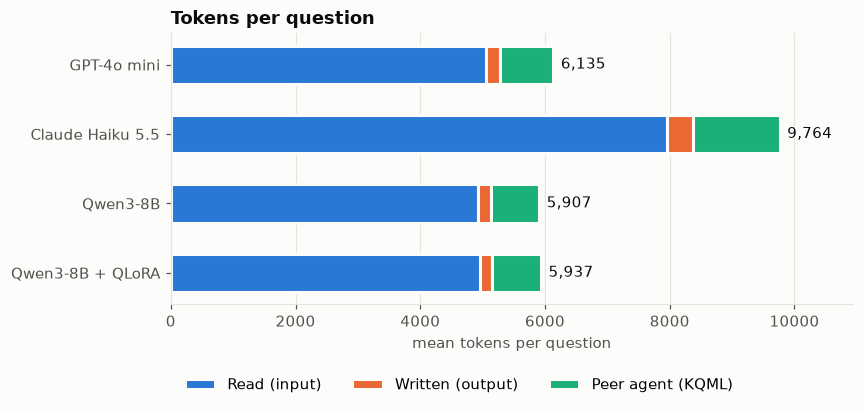

In [13]:
# Stacked bar: what a question's tokens are made of.
parts = [("tokens_in", "Read (input)", "#2a78d6"),
         ("tokens_out", "Written (output)", "#eb6834"),
         ("peer_tokens", "Peer agent (KQML)", "#1baf7a")]
means = df.groupby("model", observed=True)[[p[0] for p in parts]].mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(MODELS))[::-1]
left = np.zeros(len(MODELS))
for col, label, color in parts:
    ax.barh(y, means[col], left=left, height=0.55, color=color, label=label,
            edgecolor="#fcfcfb", linewidth=2)
    left += means[col].values
for yi, total in zip(y, left):
    ax.text(total + 120, yi, f"{total:,.0f}", va="center", color=TEXT)
ax.set_yticks(y, [MODEL_LABEL[m] for m in MODELS])
ax.set_xlabel("mean tokens per question")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.12)
ax.set_title("Tokens per question")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22))
save(fig, "tokens_per_question")

### 2.2 Agent-001 vs Agent-002

Both agents get the same questions but hold different parts of the data, so they do not need the
peer equally often. The difference shows up in `peer_tokens`.

In [14]:
by_agent = df.groupby(["model", "agent_name"], observed=True).agg(
    kqml_share=("used_kqml", "mean"),
    tokens_in=("tokens_in", "mean"),
    tokens_out=("tokens_out", "mean"),
    peer_tokens=("peer_tokens", "mean"),
    tokens_total=("tokens_total", "mean"),
)
by_agent.rename(index=MODEL_LABEL, level=0).round(2)

kqml_share  tokens_in  tokens_out  peer_tokens  tokens_total
model            agent_name                                                              
GPT-4o mini      Agent-001         0.72    5054.99      214.29      1061.19       6330.46
                 Agent-002         0.34    5057.89      214.65       666.60       5939.13
Claude Haiku 5.5 Agent-001         0.74    7959.38      407.44      1731.73      10098.55
                 Agent-002         0.34    7964.09      408.57      1056.53       9429.20
Qwen3-8B         Agent-001         0.75    4932.31      199.82      1013.40       6145.53
                 Agent-002         0.34    4932.61      199.82       535.80       5668.23
Qwen3-8B + QLoRA Agent-001         0.75    4950.21      192.08      1027.90       6170.19
                 Agent-002         0.36    4950.65      192.08       560.28       5703.01

### 2.3 Tokens by query category

In [15]:
tok_cat = (df.pivot_table(index="expected_category", columns="model", values="tokens_total",
                          aggfunc="mean", observed=True)
             .reindex(CATEGORIES)[MODELS])
tok_cat.columns = [MODEL_LABEL[m] for m in MODELS]
tok_cat.round(0)

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
expected_category,,,,
DATA_LOOKUP,4788.0,8042.0,5091.0,5086.0
GEOMETRY_LOOKUP,3406.0,6252.0,3693.0,3739.0
SPATIAL_ADJACENCY,6822.0,11400.0,7045.0,7031.0
SPATIAL_DIRECTION,8277.0,10844.0,6681.0,6668.0
SPATIAL_DISTANCE,7248.0,12028.0,7186.0,7457.0
SPATIAL_OPERATION,6608.0,10640.0,6581.0,6579.0
SPATIAL_RELATIONSHIP_BUFFER,7988.0,12214.0,6541.0,6537.0
UNRELATED,2143.0,3505.0,2778.0,2779.0


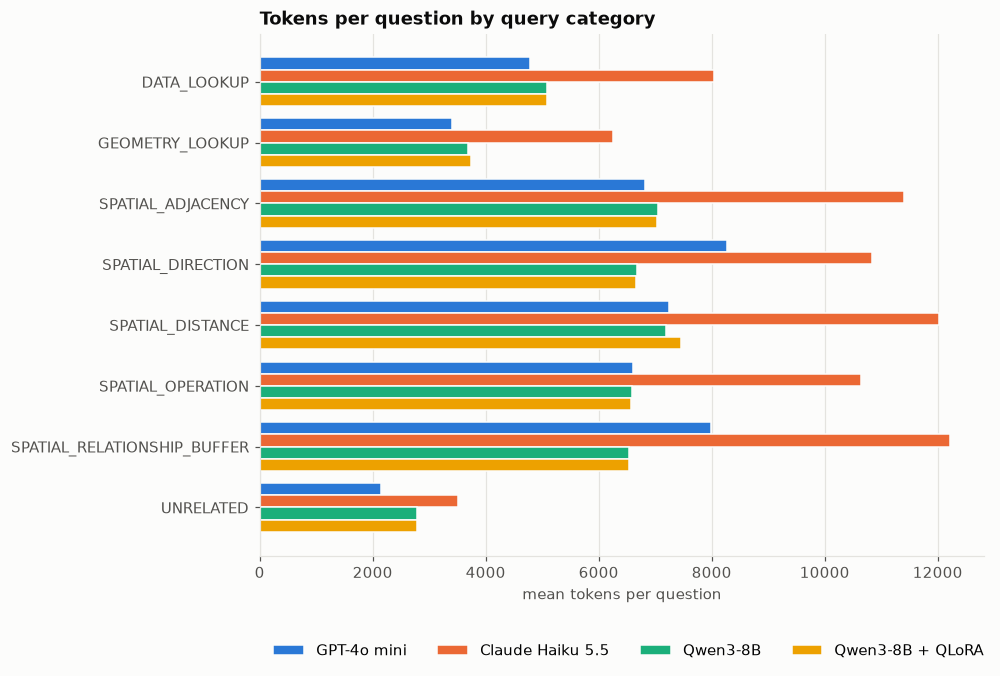

In [16]:
def grouped_barh(table, xlabel, title, name):
    # One row per category, one bar per model in fixed model order.
    fig, ax = plt.subplots(figsize=(8.5, 0.62 * len(table) + 1.2))
    n = len(MODELS)
    h = 0.8 / n
    y = np.arange(len(table))[::-1]
    for i, m in enumerate(MODELS):
        ax.barh(y + (n / 2 - i - 0.5) * h, table[MODEL_LABEL[m]], height=h,
                color=MODEL_COLOR[m], label=MODEL_LABEL[m], edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.08 - 0.5 / len(table)))
    save(fig, name)


grouped_barh(tok_cat, "mean tokens per question", "Tokens per question by query category",
             "tokens_by_category")

### 2.4 Cost

`cost_usd` is the API cost logged by the test tool. The two Qwen models run locally, so their API cost is
0; their real cost is hardware and electricity, which is not in the data.

In [17]:
cost = df.groupby("model", observed=True).agg(
    asks=("qid", "size"),
    cost_usd_total=("cost_usd", "sum"),
    cost_usd_per_question=("cost_usd", "mean"),
    tokens_total_sum=("tokens_total", "sum"),
)
cost["cost_usd_per_1000_questions"] = cost["cost_usd_per_question"] * 1000
cost["usd_per_million_tokens"] = cost["cost_usd_total"] / cost["tokens_total_sum"] * 1e6
cost.rename(index=MODEL_LABEL).round(4)

,asks,cost_usd_total,cost_usd_per_question,tokens_total_sum,cost_usd_per_1000_questions,usd_per_million_tokens
model,,,,,,
GPT-4o mini,1000,1.0314,0.0010,6134799,1.0314,0.1681
Claude Haiku 5.5,1000,11.7556,0.0118,9763875,11.7556,1.2040
Qwen3-8B,1000,0.0000,0.0000,5906880,0.0000,0.0000
Qwen3-8B + QLoRA,1000,0.0000,0.0000,5936600,0.0000,0.0000


## 3. Response time

`wall_ms` is the time the user waits for the whole question. It splits into

| part | column |
|---|---|
| classify the question | `ms_classify` |
| extract places, years, attributes | `ms_extract` |
| write + check + run SQL (incl. retries) | `ms_sql` |
| KQML exchange with the peer | `ms_kqml` |
| other agent work (merging, formatting) | `ms_agent − sum of the four steps` |
| outside the agent (HTTP, test harness) | `wall_ms − ms_agent` |

**Note for the thesis:** the Qwen models ran on local hardware, the GPT and Claude models through
their APIs. Response times therefore compare *deployments* (model + hardware/network), not the models alone.
State the local hardware in the method chapter.

In [18]:
def p95(s):
    return s.quantile(0.95)


rt = df.groupby("model", observed=True)["wall_s"].agg(["mean", "median", p95, "min", "max", "std"])
rt.columns = ["mean_s", "median_s", "p95_s", "min_s", "max_s", "std_s"]
rt.rename(index=MODEL_LABEL).round(2)

,mean_s,median_s,p95_s,min_s,max_s,std_s
model,,,,,,
GPT-4o mini,9.25,9.33,15.87,2.63,23.96,3.83
Claude Haiku 5.5,8.82,8.85,16.19,2.80,25.77,3.65
Qwen3-8B,17.06,17.23,29.14,2.37,38.54,6.33
Qwen3-8B + QLoRA,19.00,19.15,33.64,2.43,43.74,7.42


In [19]:
outside = df["ms_outside"]
print(f"time outside the agent: median {outside.median():.0f} ms, "
      f"IQR {outside.quantile(.25):.0f}-{outside.quantile(.75):.0f} ms, max {outside.max():.0f} ms")
print("This part is nearly constant, so it adds the same offset to every model.")

time outside the agent: median 2080 ms, IQR 2068-2096 ms, max 3252 ms
This part is nearly constant, so it adds the same offset to every model.


### 3.1 Where the time goes

,Classify,Extract,SQL,KQML,Other agent work,Outside agent,Total
model,,,,,,,
GPT-4o mini,0.83,0.94,3.02,2.03,0.35,2.08,9.25
Claude Haiku 5.5,1.04,0.91,2.47,1.99,0.33,2.08,8.82
Qwen3-8B,2.28,2.87,6.36,2.89,0.55,2.11,17.06
Qwen3-8B + QLoRA,2.62,3.06,7.36,3.20,0.63,2.13,19.00


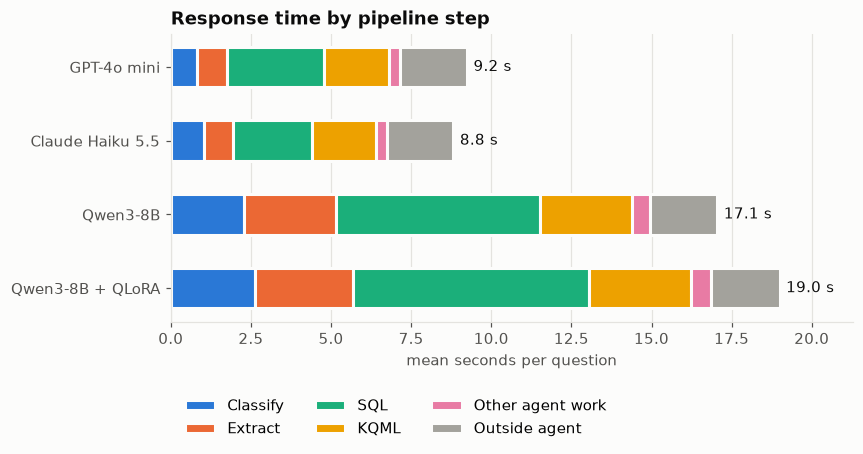

In [20]:
STEP_PARTS = [("ms_classify", "Classify", "#2a78d6"),
              ("ms_extract", "Extract", "#eb6834"),
              ("ms_sql", "SQL", "#1baf7a"),
              ("ms_kqml", "KQML", "#eda100"),
              ("ms_other", "Other agent work", "#e87ba4"),
              ("ms_outside", "Outside agent", "#a3a29c")]
step_mean = df.groupby("model", observed=True)[[p[0] for p in STEP_PARTS]].mean() / 1000

table = step_mean.copy()
table.columns = [p[1] for p in STEP_PARTS]
table["Total"] = table.sum(axis=1)
display(table.rename(index=MODEL_LABEL).round(2))

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(MODELS))[::-1]
left = np.zeros(len(MODELS))
for col, label, color in STEP_PARTS:
    ax.barh(y, step_mean[col], left=left, height=0.55, color=color, label=label,
            edgecolor="#fcfcfb", linewidth=2)
    left += step_mean[col].values
for yi, total in zip(y, left):
    ax.text(total + 0.2, yi, f"{total:.1f} s", va="center", color=TEXT)
ax.set_yticks(y, [MODEL_LABEL[m] for m in MODELS])
ax.set_xlabel("mean seconds per question")
ax.set_xlim(0, left.max() * 1.12)
ax.grid(axis="y", visible=False)
ax.set_title("Response time by pipeline step")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22))
save(fig, "time_by_step")

### 3.2 Distribution of response time

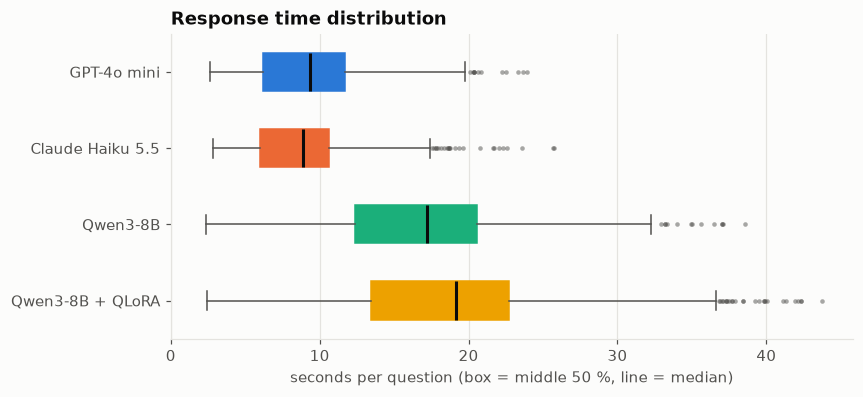

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.6))
data = [df.loc[df["model"] == m, "wall_s"] for m in MODELS]
bp = ax.boxplot(data, orientation="horizontal", widths=0.5, patch_artist=True, showfliers=True,
                medianprops=dict(color=TEXT, linewidth=2),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=TEXT_2,
                                markeredgecolor="none", alpha=0.5),
                whiskerprops=dict(color=TEXT_2), capprops=dict(color=TEXT_2))
for patch, m in zip(bp["boxes"], MODELS):
    patch.set_facecolor(MODEL_COLOR[m])
    patch.set_edgecolor(MODEL_COLOR[m])
ax.set_yticks(range(1, len(MODELS) + 1), [MODEL_LABEL[m] for m in MODELS])
ax.invert_yaxis()
ax.set_xlim(0, None)
ax.set_xlabel("seconds per question (box = middle 50 %, line = median)")
ax.grid(axis="y", visible=False)
ax.set_title("Response time distribution")
save(fig, "time_distribution")

### 3.3 Response time and question complexity

Complexity is defined **per question**, so every model is measured against the same scale:

* `sql_steps` – how many SQL steps the question needs
* `kqml_turns` – how many KQML ask/tell exchanges are needed to get the missing data

These two are the strongest drivers of time (see the correlation table below). The number of places,
years and attributes barely matters. The question's value is the median over all
40 asks of that question (4 models × 2 agents × 5 reps), so a model that makes an extra SQL attempt on
a question does not move that question to a higher tier.

| tier | rule (score = sql_steps + kqml_turns) |
|---|---|
| Low | score ≤ 1 |
| Medium | score 2–3 |
| High | score ≥ 4 |

In [22]:
DRIVERS = ["sql_steps", "kqml_turns", "llm_calls", "sql_attempts", "n_places", "n_years", "n_attributes"]
corr = pd.DataFrame({
    MODEL_LABEL[m]: [stats.spearmanr(g[c], g["wall_ms"], nan_policy="omit")[0] for c in DRIVERS]
    for m, g in df.groupby("model", observed=True)
}, index=DRIVERS)
print("Spearman correlation of each driver with response time (wall_ms), per model:")
corr.round(2)

Spearman correlation of each driver with response time (wall_ms), per model:


,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
sql_steps,0.77,0.74,0.74,0.78
kqml_turns,0.81,0.83,0.69,0.69
llm_calls,0.83,0.77,0.79,0.80
sql_attempts,0.78,0.71,0.75,0.76
n_places,0.03,0.04,-0.01,0.00
n_years,0.07,0.10,0.07,0.08
n_attributes,-0.03,-0.01,-0.03,-0.04


In [23]:
question = df.groupby("qid").agg(
    question=("question", "first"),
    category=("expected_category", "first"),
    sql_steps=("sql_steps", "median"),
    kqml_turns=("kqml_turns", "median"),
)
question["complexity_score"] = question["sql_steps"] + question["kqml_turns"]
question["complexity"] = pd.cut(question["complexity_score"], bins=[-np.inf, 1, 3, np.inf],
                                labels=["Low", "Medium", "High"])
df = df.drop(columns=["complexity", "complexity_score"], errors="ignore").merge(
    question[["complexity", "complexity_score"]], left_on="qid", right_index=True)

print("questions per complexity tier:")
print(question["complexity"].value_counts().reindex(["Low", "Medium", "High"]))
print()
print(pd.crosstab(question["category"].fillna("(none)"), question["complexity"]))

questions per complexity tier:
complexity
Low       15
Medium    65
High      20
Name: count, dtype: int64

complexity                   Low  Medium  High
category                                      
(none)                         0       1     1
DATA_LOOKUP                    5      12     1
GEOMETRY_LOOKUP                7       4     0
SPATIAL_ADJACENCY              0      10     2
SPATIAL_DIRECTION              0      10     1
SPATIAL_DISTANCE               0      10     1
SPATIAL_OPERATION              0      12     5
SPATIAL_RELATIONSHIP_BUFFER    0       4     9
UNRELATED                      3       2     0


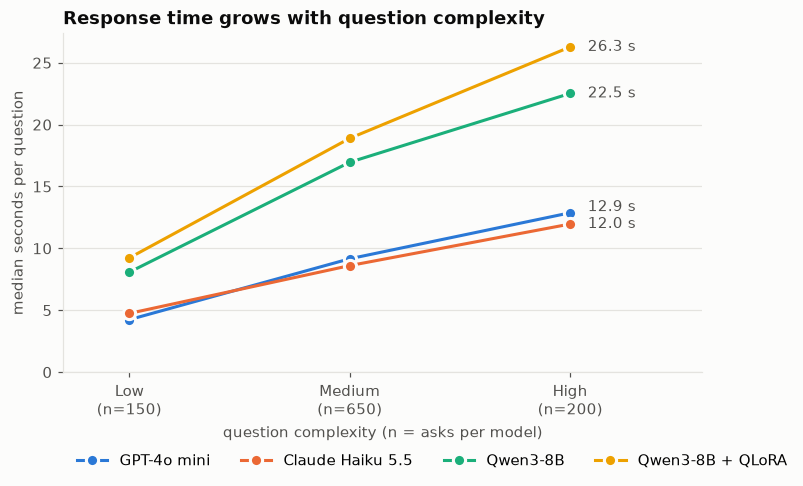

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
complexity,,,,
Low,4.24,4.74,8.07,9.22
Medium,9.16,8.61,16.96,18.89
High,12.88,11.97,22.52,26.28


In [24]:
def median_line_chart(column, order, xlabel, title, name):
    table = (df.pivot_table(index=column, columns="model", values="wall_s",
                            aggfunc="median", observed=True)
               .reindex(order)[MODELS])
    counts = df[df["model"] == MODELS[0]].groupby(column, observed=True).size().reindex(order)

    fig, ax = plt.subplots(figsize=(7.5, 4))
    x = np.arange(len(order))
    for m in MODELS:
        ax.plot(x, table[m], color=MODEL_COLOR[m], linewidth=2, marker="o", markersize=8,
                markeredgecolor="#fcfcfb", markeredgewidth=2, label=MODEL_LABEL[m])
    ax.set_ylim(0, None)

    # Label each line's last point; push labels at the same x apart so they don't overlap.
    min_gap = 0.05 * ax.get_ylim()[1]
    ends = sorted((order.index(table[m].last_valid_index()), table[m].dropna().iloc[-1]) for m in MODELS)
    placed = {}
    for xi, value in ends:
        y_label = max(value, placed.get(xi, -np.inf) + min_gap)
        placed[xi] = y_label
        ax.annotate(f"{value:.1f} s", (xi, value), xytext=(xi + 0.08, y_label),
                    va="center", color=TEXT_2)

    ax.set_xticks(x, [f"{o}\n(n={counts.get(o, 0):.0f})" for o in order])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("median seconds per question")
    ax.set_xlim(-0.3, len(order) - 0.4)
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2))
    save(fig, name)
    out = table.copy()
    out.columns = [MODEL_LABEL[m] for m in MODELS]
    return out.round(2)


median_line_chart("complexity", ["Low", "Medium", "High"], "question complexity (n = asks per model)",
                  "Response time grows with question complexity", "time_by_complexity")

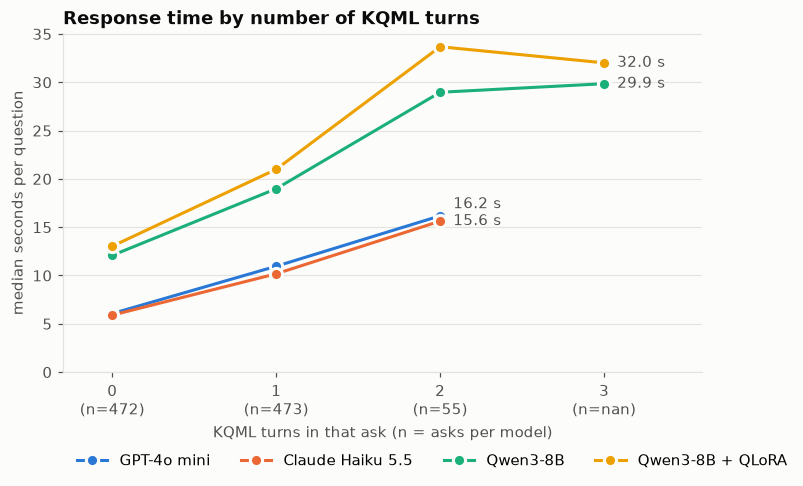

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
kqml_turns,,,,
0,6.06,5.90,12.08,13.03
1,10.96,10.18,18.98,21.00
2,16.18,15.63,28.97,33.68
3,NaN,NaN,29.85,32.01


In [25]:
median_line_chart("kqml_turns", [0, 1, 2, 3], "KQML turns in that ask (n = asks per model)",
                  "Response time by number of KQML turns", "time_by_kqml_turns")

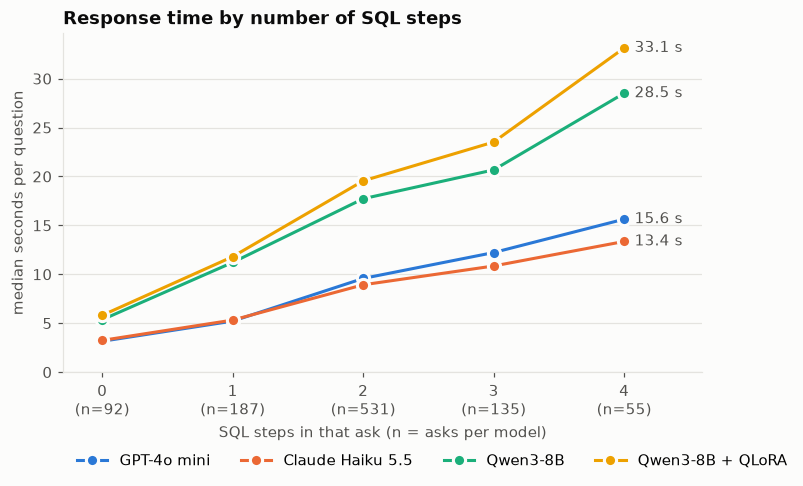

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
sql_steps,,,,
0,3.15,3.24,5.36,5.81
1,5.21,5.32,11.21,11.80
2,9.58,8.93,17.72,19.55
3,12.22,10.85,20.67,23.52
4,15.63,13.36,28.51,33.13


In [26]:
median_line_chart("sql_steps", [0, 1, 2, 3, 4], "SQL steps in that ask (n = asks per model)",
                  "Response time by number of SQL steps", "time_by_sql_steps")

How much slower each model gets from a Low to a High question – the *slope* matters for scalability as
much as the absolute time.

In [27]:
tier = df.pivot_table(index="model", columns="complexity", values="wall_s",
                      aggfunc="median", observed=True)[["Low", "Medium", "High"]]
tier["High / Low"] = tier["High"] / tier["Low"]
tier["High - Low (s)"] = tier["High"] - tier["Low"]
tier.rename(index=MODEL_LABEL).round(2)

complexity,Low,Medium,High,High / Low,High - Low (s)
model,,,,,
GPT-4o mini,4.24,9.16,12.88,3.04,8.64
Claude Haiku 5.5,4.74,8.61,11.97,2.52,7.22
Qwen3-8B,8.07,16.96,22.52,2.79,14.45
Qwen3-8B + QLoRA,9.22,18.89,26.28,2.85,17.05


### 3.4 Response time by query category

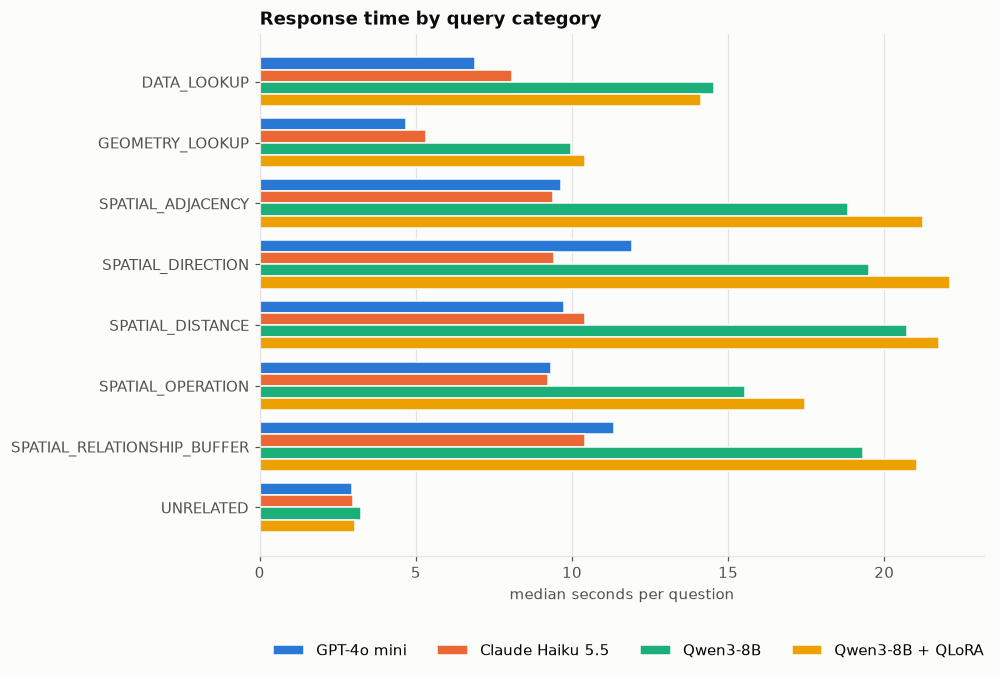

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
expected_category,,,,
DATA_LOOKUP,6.90,8.07,14.56,14.12
GEOMETRY_LOOKUP,4.69,5.31,9.96,10.41
SPATIAL_ADJACENCY,9.65,9.40,18.84,21.25
SPATIAL_DIRECTION,11.91,9.42,19.50,22.10
SPATIAL_DISTANCE,9.73,10.41,20.72,21.74
SPATIAL_OPERATION,9.33,9.24,15.54,17.46
SPATIAL_RELATIONSHIP_BUFFER,11.36,10.41,19.31,21.03
UNRELATED,2.96,2.99,3.23,3.04


In [28]:
time_cat = (df.pivot_table(index="expected_category", columns="model", values="wall_s",
                           aggfunc="median", observed=True)
              .reindex(CATEGORIES)[MODELS])
time_cat.columns = [MODEL_LABEL[m] for m in MODELS]
grouped_barh(time_cat, "median seconds per question", "Response time by query category",
             "time_by_category")
time_cat.round(2)

### 3.5 Agent-001 vs Agent-002

In [29]:
df.pivot_table(index="model", columns="agent_name", values="wall_s",
               aggfunc=["median", "mean"], observed=True).rename(index=MODEL_LABEL).round(2)

median                mean          
agent_name       Agent-001 Agent-002 Agent-001 Agent-002
model                                                   
GPT-4o mini          10.35      8.40     10.06      8.43
Claude Haiku 5.5      9.64      7.18      9.60      8.04
Qwen3-8B             18.17     16.72     17.96     16.15
Qwen3-8B + QLoRA     20.02     18.54     19.94     18.06

## 4. Are the differences between models significant?

Each question is a paired observation: all four models answered the same 100 questions. Per model, the
10 asks of a question (2 agents × 5 reps) are averaged into one value per question. Then

* **Friedman test** – do the four models differ at all?
* **Wilcoxon signed-rank, Holm-corrected** – which pairs differ? The most relevant pair is
  *Qwen3-8B vs Qwen3-8B + QLoRA*, which shows what fine-tuning changed.

In [30]:
from itertools import combinations


def holm(pvalues):
    # Holm–Bonferroni adjusted p-values, same order as the input.
    p = np.asarray(pvalues)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(running, 1.0)
    return adjusted


def compare_models(metric):
    per_q = df.pivot_table(index="qid", columns="model", values=metric,
                           aggfunc="mean", observed=True)[MODELS]
    friedman = stats.friedmanchisquare(*[per_q[m] for m in MODELS])
    print(f"{metric}: Friedman chi2 = {friedman.statistic:.1f}, p = {friedman.pvalue:.2e} "
          f"(n = {len(per_q)} questions)")

    rows = []
    for a, b in combinations(MODELS, 2):
        d = per_q[a] - per_q[b]
        w = stats.wilcoxon(per_q[a], per_q[b])
        rows.append({"model A": MODEL_LABEL[a], "model B": MODEL_LABEL[b],
                     "median A": per_q[a].median(), "median B": per_q[b].median(),
                     "median diff (A - B)": d.median(),
                     "A lower on % of questions": (d < 0).mean() * 100,
                     "p": w.pvalue})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"])
    out["significant (p<0.05)"] = out["p (Holm)"] < 0.05
    return out


P_FORMAT = {"p": "{:.2e}", "p (Holm)": "{:.2e}"}

sig_tokens = compare_models("tokens_total")
sig_tokens.style.format(P_FORMAT, precision=2)

tokens_total: Friedman chi2 = 209.4, p = 3.88e-45 (n = 100 questions)


,model A,model B,median A,median B,median diff (A - B),A lower on % of questions,p,p (Holm),significant (p<0.05)
0,GPT-4o mini,Claude Haiku 5.5,6185.00,10060.45,-3496.15,100.00,3.90e-18,2.34e-17,True
1,GPT-4o mini,Qwen3-8B,6185.00,6035.00,-139.15,75.00,1.53e-01,1.80e-01,False
2,GPT-4o mini,Qwen3-8B + QLoRA,6185.00,6024.00,-134.45,76.00,9.01e-02,1.80e-01,False
3,Claude Haiku 5.5,Qwen3-8B,10060.45,6035.00,3810.70,1.00,5.94e-18,2.97e-17,True
4,Claude Haiku 5.5,Qwen3-8B + QLoRA,10060.45,6024.00,3821.70,1.00,6.12e-18,2.97e-17,True
5,Qwen3-8B,Qwen3-8B + QLoRA,6035.00,6024.00,5.00,20.00,5.66e-11,1.70e-10,True


In [31]:
sig_time = compare_models("wall_s")
sig_time.style.format(P_FORMAT, precision=2)

wall_s: Friedman chi2 = 249.3, p = 9.38e-54 (n = 100 questions)


,model A,model B,median A,median B,median diff (A - B),A lower on % of questions,p,p (Holm),significant (p<0.05)
0,GPT-4o mini,Claude Haiku 5.5,9.02,8.42,0.50,26.00,1.34e-05,1.34e-05,True
1,GPT-4o mini,Qwen3-8B,9.02,17.83,-7.74,98.00,4.27e-18,2.56e-17,True
2,GPT-4o mini,Qwen3-8B + QLoRA,9.02,19.32,-9.73,98.00,4.53e-18,2.56e-17,True
3,Claude Haiku 5.5,Qwen3-8B,8.42,17.83,-8.77,98.00,4.40e-18,2.56e-17,True
4,Claude Haiku 5.5,Qwen3-8B + QLoRA,8.42,19.32,-10.44,97.00,4.67e-18,2.56e-17,True
5,Qwen3-8B,Qwen3-8B + QLoRA,17.83,19.32,-1.82,95.00,4.60e-17,9.21e-17,True


## 5. Spot-check list

The asks with the most tokens and the longest response time per model. Open them and check
the cause (SQL retries, many KQML turns, or a long answer).

In [32]:
SPOT_COLS = ["model", "qid", "agent_name", "rep", "question", "expected_category", "answer_status",
             "tokens_total", "wall_s", "sql_attempts", "kqml_turns", "llm_calls", "ms_sql", "ms_kqml"]
top_tokens = df.sort_values("tokens_total", ascending=False).groupby("model", observed=True).head(5)[SPOT_COLS]
top_time = df.sort_values("wall_s", ascending=False).groupby("model", observed=True).head(5)[SPOT_COLS]
display(top_tokens)
display(top_time)

,model,qid,agent_name,rep,question,expected_category,answer_status,tokens_total,wall_s,sql_attempts,kqml_turns,llm_calls,ms_sql,ms_kqml
2508,claude-haiku,t051,Agent-002,4,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,25763,25.6401,4.0,1,6,17128.5,4405.2
2505,claude-haiku,t051,Agent-002,1,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,22174,17.5520,3.0,1,5,9178.9,4100.1
2509,claude-haiku,t051,Agent-002,5,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,22088,17.9637,3.0,1,5,9348.7,4257.3
2507,claude-haiku,t051,Agent-002,3,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,21941,16.3849,3.0,1,5,8573.7,3923.7
2506,claude-haiku,t051,Agent-002,2,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,21798,16.5417,3.0,1,5,8585.4,3712.0
3507,gpt-4o-mini,t051,Agent-002,3,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,14102,12.8046,4.0,1,6,5243.1,3416.1
3508,gpt-4o-mini,t051,Agent-002,4,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,14102,18.5997,4.0,1,6,11105.8,3394.4
3509,gpt-4o-mini,t051,Agent-002,5,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,14102,13.0780,4.0,1,6,5366.0,3751.9
3506,gpt-4o-mini,t051,Agent-002,2,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,14088,13.3913,4.0,1,6,5455.6,3540.7
3505,gpt-4o-mini,t051,Agent-002,1,Which cities lie north of Baden-Württemberg?,SPATIAL_RELATIONSHIP_BUFFER,complete,14088,14.1030,4.0,1,6,6212.3,3976.3


,model,qid,agent_name,rep,question,expected_category,answer_status,tokens_total,wall_s,sql_attempts,kqml_turns,llm_calls,ms_sql,ms_kqml
934,qwen3-8b-lora,t094,Agent-001,5,Give me the live births in 2016 of the states ...,SPATIAL_DISTANCE,partial-complete,11723,43.7385,5.0,2,7,19769.8,12250.1
521,qwen3-8b-lora,t053,Agent-001,2,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5733,42.3220,3.0,3,5,13276.0,18371.6
523,qwen3-8b-lora,t053,Agent-001,4,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5733,42.2968,3.0,3,5,13248.9,17760.6
914,qwen3-8b-lora,t092,Agent-001,5,Which states are within 40 km of Saarland?,SPATIAL_DISTANCE,complete,6900,42.1028,2.0,1,4,9520.3,3829.1
919,qwen3-8b-lora,t092,Agent-002,5,Which states are within 40 km of Saarland?,SPATIAL_DISTANCE,complete,5894,41.9553,2.0,0,4,8974.2,0.0
1521,qwen3-8b,t053,Agent-001,2,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5739,38.5351,3.0,3,5,10753.6,17033.7
1524,qwen3-8b,t053,Agent-001,5,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5739,37.0953,3.0,3,5,10987.4,16638.0
1522,qwen3-8b,t053,Agent-001,3,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5739,37.0454,3.0,3,5,10480.4,16530.8
1520,qwen3-8b,t053,Agent-001,1,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5739,37.0116,3.0,3,5,10455.0,16957.3
1523,qwen3-8b,t053,Agent-001,4,What cities are south of Niedersachsen?,SPATIAL_RELATIONSHIP_BUFFER,complete,5739,36.4680,3.0,3,5,10397.3,15898.2


## 6. Export

All tables go to one Excel file and all charts to PNG (300 dpi), in `outputs/01_tokens_response_time/`.

In [33]:
def labelled(t):
    return t.rename(index=MODEL_LABEL)


with pd.ExcelWriter(OUT_DIR / "tokens_response_time.xlsx") as xl:
    labelled(tok).round(2).to_excel(xl, sheet_name="tokens_per_model")
    labelled(by_agent).round(2).to_excel(xl, sheet_name="tokens_per_agent")
    tok_cat.round(1).to_excel(xl, sheet_name="tokens_by_category")
    labelled(cost).round(6).to_excel(xl, sheet_name="cost")
    labelled(rt).round(3).to_excel(xl, sheet_name="time_per_model")
    labelled(table).round(3).to_excel(xl, sheet_name="time_by_step")
    labelled(tier).round(3).to_excel(xl, sheet_name="time_by_complexity")
    time_cat.round(3).to_excel(xl, sheet_name="time_by_category")
    corr.round(3).to_excel(xl, sheet_name="time_drivers_spearman")
    sig_tokens.to_excel(xl, sheet_name="stats_tokens", index=False)
    sig_time.to_excel(xl, sheet_name="stats_time", index=False)
    question.to_excel(xl, sheet_name="question_complexity")
    top_tokens.to_excel(xl, sheet_name="spot_top_tokens", index=False)
    top_time.to_excel(xl, sheet_name="spot_top_time", index=False)

for f in sorted(OUT_DIR.iterdir()):
    print(f)

outputs\01_tokens_response_time\time_by_category.png
outputs\01_tokens_response_time\time_by_complexity.png
outputs\01_tokens_response_time\time_by_kqml_turns.png
outputs\01_tokens_response_time\time_by_sql_steps.png
outputs\01_tokens_response_time\time_by_step.png
outputs\01_tokens_response_time\time_distribution.png
outputs\01_tokens_response_time\tokens_by_category.png
outputs\01_tokens_response_time\tokens_per_question.png
outputs\01_tokens_response_time\tokens_response_time.xlsx
